### 🤖 Implement ReAct with LangGraph-What is ReAct?
ReAct (Reasoning + Acting) is a framework where an LLM:

- Reasons step-by-step (e.g. decomposes questions, makes decisions)

- Acts by calling tools like search, calculators, or retrievers

This makes it perfect for Agentic RAG:
✅ Think → Retrieve → Observe → Reflect → Final Answer

In [2]:
import os
from typing import Annotated, Sequence, TypedDict
# 1. External tools setup
import wikipedia
# (Always set user_agent right after import to prevent Wikipedia blocking):
wikipedia.set_user_agent("MyLangChainApp/1.0 (contact@example.com)")
# 2. LangChain Core (Primitives, Messages, Tools)
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage
from langchain_core.tools import Tool, tool
# 3. LangChain Models, Loaders, Splitters & Community Integrations
from langchain.chat_models import init_chat_model
from langchain_openai import OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import WebBaseLoader
from langchain_community.vectorstores import FAISS
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
# 4. LangGraph (Graph construction & Prebuilt Agents)
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.graph.message import add_messages
from langgraph.prebuilt import create_react_agent
from langchain.agents import create_agent

C:\Users\15715\AppData\Local\Temp\ipykernel_20652\2215376462.py:14: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader
USER_AGENT environment variable not set, consider setting it to identify your requests.


In [3]:
import os
from dotenv import load_dotenv
load_dotenv()
os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
llm=init_chat_model("openai:gpt-4o")
#llm = ChatGroq(model="llama-3.3-70b-versatile")
llm

ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.6.12', 'langchain': '1.4.6', 'langchain-openai': '1.7.2'}}, profile={'name': 'GPT-4o', 'release_date': '2024-05-13', 'last_updated': '2024-08-06', 'open_weights': False, 'max_input_tokens': 128000, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_choice': True, 'tool_call_streaming': True}, client=<openai.resources.chat.completions.completions.Completions object at 0x0000025EA4339E80>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x0000025EA433A900>, root_client=<openai.OpenAI object at 0x0000025EA4339010>, ro

In [4]:
# --------------------------
# 1. Create Retriever Tool
# --------------------------

# Load content from blog
docs = WebBaseLoader("https://lilianweng.github.io/posts/2023-06-23-agent/").load()
splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
chunks = splitter.split_documents(docs)

embedding = OpenAIEmbeddings()
vectorstore = FAISS.from_documents(chunks, embedding)
retriever = vectorstore.as_retriever()
retriever.invoke("what are autonomous agents")

[Document(id='a3290bbc-a37a-414a-b391-ffb81b8ae59f', metadata={'source': 'https://lilianweng.github.io/posts/2023-06-23-agent/', 'title': "LLM Powered Autonomous Agents | Lil'Log", 'description': 'Building agents with LLM (large language model) as its core controller is a cool concept. Several proof-of-concepts demos, such as AutoGPT, GPT-Engineer and BabyAGI, serve as inspiring examples. The potentiality of LLM extends beyond generating well-written copies, stories, essays and programs; it can be framed as a powerful general problem solver.\nAgent System Overview\nIn a LLM-powered autonomous agent system, LLM functions as the agent’s brain, complemented by several key components:\n\nPlanning\n\nSubgoal and decomposition: The agent breaks down large tasks into smaller, manageable subgoals, enabling efficient handling of complex tasks.\nReflection and refinement: The agent can do self-criticism and self-reflection over past actions, learn from mistakes and refine them for future steps, 

In [5]:
def retriever_tool_func(query: str) -> str:
    print("📚 Using RAGRetriever tool")
    docs = retriever.invoke(query)
    return "\n".join([doc.page_content for doc in docs])

retriever_tool_func("what are autonomous agents")

📚 Using RAGRetriever tool


'Boiko et al. (2023) also looked into LLM-empowered agents for scientific discovery, to handle autonomous design, planning, and performance of complex scientific experiments. This agent can use tools to browse the Internet, read documentation, execute code, call robotics experimentation APIs and leverage other LLMs.\nFor example, when requested to "develop a novel anticancer drug", the model came up with the following reasoning steps:\nCitation#\nCited as:\n\nWeng, Lilian. (Jun 2023). “LLM-powered Autonomous Agents”. Lil’Log. https://lilianweng.github.io/posts/2023-06-23-agent/.\nOr\n@article{weng2023agent,\n  title   = "LLM-powered Autonomous Agents",\n  author  = "Weng, Lilian",\n  journal = "lilianweng.github.io",\n  year    = "2023",\n  month   = "Jun",\n  url     = "https://lilianweng.github.io/posts/2023-06-23-agent/"\n}\nReferences#\n[1] Wei et al. “Chain of thought prompting elicits reasoning in large language models.” NeurIPS 2022\n[2] Yao et al. “Tree of Thoughts: Dliberate P

In [6]:
from langchain_core.tools import Tool
retriever_tool=Tool(
    name="RAGRetriever",
    description="Use this tool to fetch relevant knowledge base info",
    func=retriever_tool_func
)
retriever_tool
print(retriever_tool.name)

RAGRetriever


In [7]:
# Wikipedia tool
wiki_tool = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())
wiki_tool

WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper(wiki_client=<module 'wikipedia' from 'c:\\Users\\15715\\anaconda3\\Lib\\site-packages\\wikipedia\\__init__.py'>, top_k_results=3, lang='en', load_all_available_meta=False, doc_content_chars_max=4000))

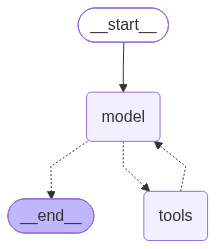

In [8]:
# ----------------------------
# 2. Define the Agent Node
# ----------------------------



tools = [retriever_tool, wiki_tool]

## create the native Langgraph react agent
react_node=create_agent(llm,tools)
react_node

In [9]:
# --------------------------
# 3. LangGraph Agent State
# --------------------------

class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]

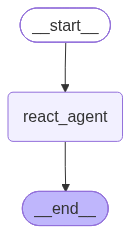

In [10]:
# --------------------------
# 4. Build LangGraph Graph
# --------------------------

builder = StateGraph(AgentState)

builder.add_node("react_agent", react_node)
builder.set_entry_point("react_agent")
builder.add_edge("react_agent", END)

graph = builder.compile()
graph

In [11]:

# --------------------------
# 5. Run the ReAct Agent
# --------------------------

if __name__ == "__main__":
    user_query = "What is an agent loop and how does Wikipedia describe autonomous agents?"
    state = {"messages": [HumanMessage(content=user_query)]}
    result = graph.invoke(state)

    print("\n✅ Final Answer:\n", result["messages"][-1].content)

📚 Using RAGRetriever tool

✅ Final Answer:
 ### Agent Loop

An agent loop refers to the iterative process in which an agent (such as a software or AI agent) interacts with its environment, performs tasks, and learns from its experiences. In a typical agent loop, the agent perceives the environment, takes actions based on its current knowledge or policy, observes the outcomes, and updates its knowledge base or policy accordingly. This cycle enables the agent to improve its performance over time. For example, in reinforcement learning scenarios, this loop is critical as the agent improves by trial and error interactions with the environment, refining its actions to achieve better outcomes.

### Autonomous Agents (Based on Wikipedia)

**Autonomous agents** are artificial intelligence (AI) systems that can perform complex tasks independently. These agents have several key attributes:

- **Goal-Directed Behavior:** They are designed to pursue specific goals or a set of objectives.
- **Indep

### Tool creation for RAG agents with langgraph 
To create tools for RAG agents using LangGraph, you're essentially building LLM-invocable functions that your agent can call as part of its reasoning + acting loop (ReAct).

LangGraph uses the Tool abstraction from LangChain and fully supports tools for:

- RAG retrieval
- Search
- Wikipedia
- SQL
- Web APIs
- Calculators, etc.

#### ✅ Tool Design Requirements
A LangGraph tool must:

- Have a name
- Have a description (used by the LLM to decide when to use it)
- Have a callable func, accepting a single input (usually str) and returning str

In [12]:
import os
from typing import Annotated, Sequence, TypedDict

# 1. Wikipedia tool setup (set User-Agent to avoid Wikimedia API blocks)
import wikipedia
wikipedia.set_user_agent("MyLangChainApp/1.0 (contact@example.com)")

# 2. LangChain Core (Messages & Tools)
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage
from langchain_core.tools import Tool


# 3. Text Splitters & Embeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings

# 4. Document Loaders, Vectorstores & Community Tools
from langchain_community.document_loaders import WebBaseLoader, ArxivLoader, TextLoader
from langchain_community.vectorstores import FAISS
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper

# 5. LangGraph (Graphs & Agents)
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.graph.message import add_messages
from langgraph.prebuilt import create_react_agent

In [ ]:
llm

ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.6.12', 'langchain': '1.4.6', 'langchain-openai': '1.7.2'}}, profile={'name': 'GPT-4o', 'release_date': '2024-05-13', 'last_updated': '2024-08-06', 'open_weights': False, 'max_input_tokens': 128000, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_choice': True, 'tool_call_streaming': True}, client=<openai.resources.chat.completions.completions.Completions object at 0x000001683A90B230>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x000001683A90BCB0>, root_client=<openai.OpenAI object at 0x000001683A90A3C0>, ro

In [13]:
from langchain_core.tools import Tool
### Generic function to create a retireval tool
def make_retriever_tool_from_text(file,name,desc):
    docs=TextLoader(file,encoding="utf-8").load()
    chunks = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50).split_documents(docs)
    vs = FAISS.from_documents(chunks, OpenAIEmbeddings())
    retriever = vs.as_retriever()

    def tool_func(query:str)->str:
        print(f"📚 Using tool: {name}")
        results = retriever.invoke(query)
        return "\n\n".join(doc.page_content for doc in results)
    
    return Tool(name=name,description=desc,func=tool_func)


# Wikipedia Tool
# wik_tool = WikipediaQueryRun(api_wrapper=api_wrapper)
# wiki_tool = Tool(
#     name="Wikipedia",
#     description="Use this tool to fetch general world knowledge from Wikipedia.",
#     func=wik_tool
# )

# ArXiv Tool
def arxiv_search(query: str) -> str:
    print("🧪 Searching ArXiv...")
    results = ArxivLoader(query).load()
    return "\n\n".join(doc.page_content[:1000] for doc in results[:2]) or "No papers found."

arxiv_tool = Tool(
    name="ArxivSearch",
    description="Use this tool to fetch recent academic papers on technical topics.",
    func=arxiv_search
)


In [14]:
internal_tool_1 = make_retriever_tool_from_text(
    "research_notes.txt",
    "InternalResearchNotes",
    "Search internal research notes for experimental results and agent designs."
)
internal_tool_1

Tool(name='InternalResearchNotes', description='Search internal research notes for experimental results and agent designs.', func=<function make_retriever_tool_from_text.<locals>.tool_func at 0x0000025EA522C9E0>)

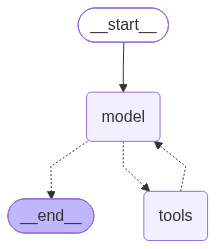

In [15]:
tools=[wiki_tool,internal_tool_1]

react_node=create_agent(llm,tools)
react_node

In [16]:
# --------------------------
# 3. LangGraph Agent State
# --------------------------

class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]

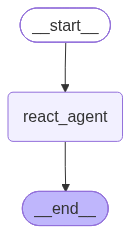

In [19]:
# --------------------------
# 4. Build LangGraph Graph
# --------------------------

builder = StateGraph(AgentState)

builder.add_node("react_agent", react_node)
builder.set_entry_point("react_agent")
builder.add_edge("react_agent", END)

graph = builder.compile()
graph

In [20]:
# --------------------------
# 5. Run the ReAct Agent
# --------------------------

if __name__ == "__main__":
    user_query = "What is an agent loop and how does Wikipedia describe autonomous agents?"
    state = {"messages": [HumanMessage(content=user_query)]}
    result = graph.invoke(state)

    print("\n✅ Final Answer:\n", result["messages"][-1].content)

📚 Using tool: InternalResearchNotes

✅ Final Answer:
 ### Agent Loop

The concept of an "agent loop" typically refers to the operational cycle of an autonomous agent or AI system within which it perceives its environment, processes this information, decides on actions, and executes them. This iterative loop allows the agent to continuously adapt to changing circumstances and is integral to the functioning of both simple and complex intelligent agents. 

The recent experimental note mentions various aspects of advanced AI experiments which might indirectly relate to how agent loops can be structured or optimized using different AI techniques such as dynamic RAG (Retrieval-Augmented Generation) pipelines or FlashAttention for reduced context latency.

### Autonomous Agents (Wikipedia Summary)

1. **Autonomous Agent**: An autonomous agent is an AI system capable of performing complex tasks without human intervention.

2. **AI Agent**: AI agents make decisions, pursue goals, and act indepe